<a href="https://colab.research.google.com/github/AsfandyarFarooqi/learning-log/blob/main/week08_recap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

satellites' distances from the Earth's centre: [25. 25. 25. 25.]
true distances, phone to S1, S2, S3, S4: [21.932 19.    21.932 19.313]
measured pseudoranges (true + b): [23.932 21.    23.932 21.313]


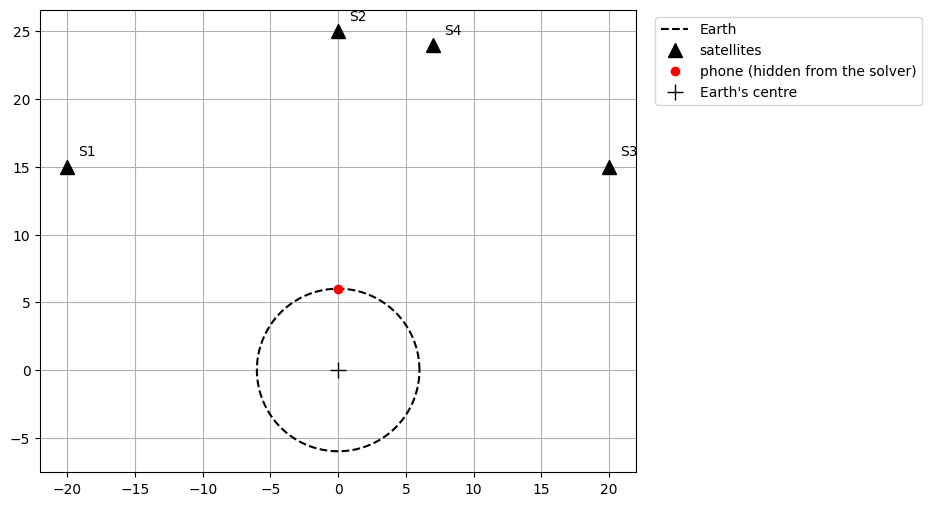

In [7]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True)

earth_radius = 6.0
sats_2d = np.array([[-20.0, 15.0], [0.0, 25.0], [20.0, 15.0], [7.0, 24.0]])
P_made_up = np.array([0.0, 6.0])
b_made_up = 2.0

true_dist = np.sqrt(np.sum((sats_2d - P_made_up)**2, axis=1))
rho_2d = true_dist + b_made_up
print("satellites' distances from the Earth's centre:", np.sqrt(np.sum(sats_2d**2, axis=1)))
print("true distances, phone to S1, S2, S3, S4:", np.round(true_dist, 3))
print("measured pseudoranges (true + b):", np.round(rho_2d, 3))

angles = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(earth_radius * np.cos(angles), earth_radius * np.sin(angles), color="black", linestyle="--", label="Earth")
ax.plot(sats_2d[:, 0], sats_2d[:, 1], "k^", markersize=10, label="satellites")
ax.plot(P_made_up[0], P_made_up[1], "ro", label="phone (hidden from the solver)")
ax.plot(0, 0, "k+", markersize=12, label="Earth's centre")
for i in range(4):
    ax.annotate("S" + str(i + 1), (sats_2d[i, 0] + 0.8, sats_2d[i, 1] + 0.8))
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()


point [0. 6.] | to S2: 19.0 | to S3: 21.932 | from the Earth's centre: 6.0
point [15.2 36.4] | to S2: 19.0 | to S3: 21.932 | from the Earth's centre: 39.446


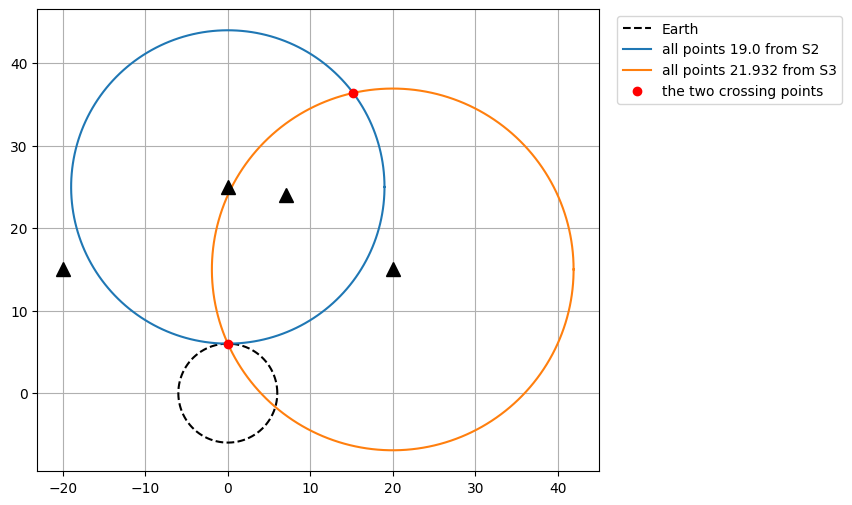

In [8]:
crossings = np.array([[0.0, 6.0], [15.2, 36.4]])
for point in crossings:
    to_S2 = np.sqrt(np.sum((point - sats_2d[1])**2))
    to_S3 = np.sqrt(np.sum((point - sats_2d[2])**2))
    from_centre = np.sqrt(np.sum(point**2))
    print("point", point, "| to S2:", round(to_S2, 3), "| to S3:", round(to_S3, 3), "| from the Earth's centre:", round(from_centre, 3))

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(earth_radius * np.cos(angles), earth_radius * np.sin(angles), color="black", linestyle="--", label="Earth")
for i in [1, 2]:
    ax.plot(sats_2d[i, 0] + true_dist[i] * np.cos(angles), sats_2d[i, 1] + true_dist[i] * np.sin(angles),
            label="all points " + str(round(true_dist[i], 3)) + " from S" + str(i + 1))
ax.plot(sats_2d[:, 0], sats_2d[:, 1], "k^", markersize=10)
ax.plot(crossings[:, 0], crossings[:, 1], "ro", label="the two crossing points")
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

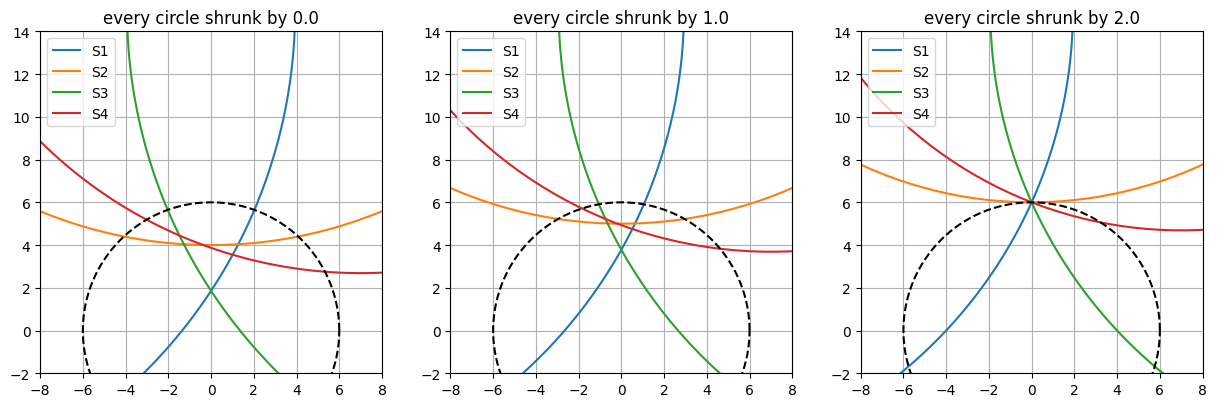

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, b_try in zip(axes, [0.0, 1.0, 2.0]):
    for i in range(4):
        radius = rho_2d[i] - b_try
        ax.plot(sats_2d[i, 0] + radius * np.cos(angles), sats_2d[i, 1] + radius * np.sin(angles), label="S" + str(i + 1))
    ax.plot(earth_radius * np.cos(angles), earth_radius * np.sin(angles), color="black", linestyle="--")
    ax.plot(sats_2d[:, 0], sats_2d[:, 1], "k^", markersize=10)
    ax.set_title("every circle shrunk by " + str(b_try))
    ax.legend(loc="upper left")
    ax.set_xlim(-8, 8)
    ax.set_ylim(-2, 14)
    ax.set_aspect("equal")
    ax.grid(True)
plt.show()

round 1 | magnitude of move: 8.023927 | X, Y, b: [-0.0023  7.3066  3.3162]
round 2 | magnitude of move: 1.781346 | X, Y, b: [-0.0004  6.0512  2.0524]
round 3 | magnitude of move: 0.073144 | X, Y, b: [0.     6.0001 2.0001]
round 4 | magnitude of move: 0.000117 | X, Y, b: [0. 6. 2.]
round 5 | magnitude of move: 0.000000 | X, Y, b: [0. 6. 2.]


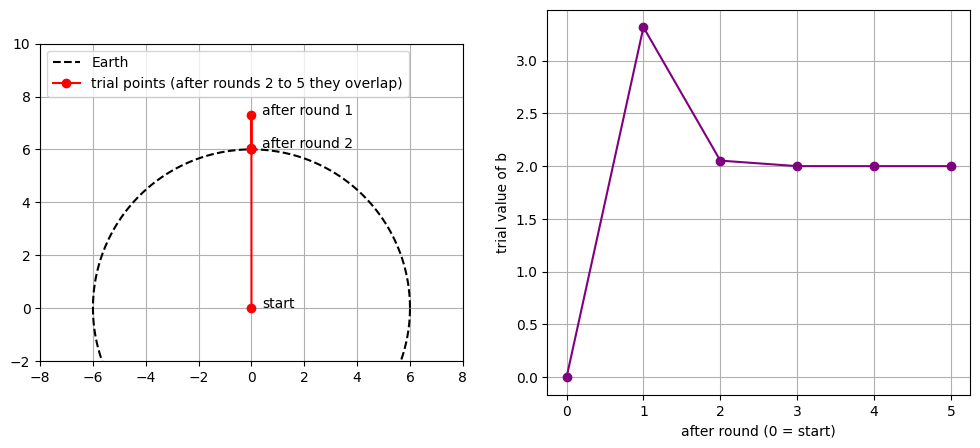

In [14]:
def gn_2d(sats, rho, x0, stop=0.0001, max_rounds=10):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    num_sats = len(rho)
    for round_no in range(1, max_rounds + 1):
        diff = x[:2] - sats
        dist0 = np.sqrt(np.sum(diff**2, axis=1))
        A = np.ones((num_sats, 3))
        A[:, :2] = diff / dist0.reshape(num_sats, 1)
        drho = rho - (dist0 + x[2])
        dx = np.linalg.solve(A.T @ A, A.T @ drho)
        x = x + dx
        path.append(x.copy())
        magnitude = np.sqrt(np.sum(dx**2))
        print("round", round_no, "| magnitude of move:", f"{magnitude:.6f}", "| X, Y, b:", np.round(x, 4) + 0.0)
        if magnitude < stop:
            break
    return x, np.array(path)

x_cold, path_cold = gn_2d(sats_2d, rho_2d, [0.0, 0.0, 0.0])

fig, (ax, ax_b) = plt.subplots(1, 2, figsize=(12, 5))
ax.plot(earth_radius * np.cos(angles), earth_radius * np.sin(angles), color="black", linestyle="--", label="Earth")
ax.plot(path_cold[:, 0], path_cold[:, 1], "o-", color="red", label="trial points (after rounds 2 to 5 they overlap)")
for k in [0, 1, 2]:
    ax.annotate("start" if k == 0 else "after round " + str(k), (path_cold[k, 0] + 0.4, path_cold[k, 1]))
ax.set_xlim(-8, 8)
ax.set_ylim(-2, 10)
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="upper left")
ax_b.plot(range(len(path_cold)), path_cold[:, 2], "o-", color="purple")
ax_b.set_xlabel("after round (0 = start)")
ax_b.set_ylabel("trial value of b")
ax_b.grid(True)
plt.show()

In [11]:
G_warm = np.array([0.3, 6.0, 1.5])
x_warm, path_warm = gn_2d(sats_2d, rho_2d, G_warm)

for name, G, x_end, path in [("cold", np.zeros(3), x_cold, path_cold), ("warm", G_warm, x_warm, path_warm)]:
    initial_error = np.sqrt(np.sum((x_end - G)**2))
    first_move = np.sqrt(np.sum((path[1] - path[0])**2))
    print(name, "| initial error:", round(initial_error, 4), "| round 1 move:", round(first_move, 4), "| rounds:", len(path) - 1, "| answer:", np.round(x_end, 4) + 0.0)

round 1 | magnitude of move: 0.582208 | X, Y, b: [0.     5.9966 1.999 ]
round 2 | magnitude of move: 0.003509 | X, Y, b: [0. 6. 2.]
round 3 | magnitude of move: 0.000001 | X, Y, b: [0. 6. 2.]
cold | initial error: 6.3246 | round 1 move: 8.0239 | rounds: 5 | answer: [0. 6. 2.]
warm | initial error: 0.5831 | round 1 move: 0.5822 | rounds: 3 | answer: [0. 6. 2.]
